# 03 · Vùng ứng viên và đặc trưng — TV4
8 đặc trưng: diện tích tương đối, độ thuôn dài, extent, độ phức tạp biên, mean, std, gradient biên và tương phản nền.

In [1]:
from pathlib import Path
import sys, json
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sar_oil import core, reference
from sar_oil.data import records, read_pair, MANIFEST
from sar_oil.experiments import OUT
def table(rows, columns):
    def value(x): return (f'{x:.3e}' if 0<abs(x)<1e-4 else f'{x:.6f}') if isinstance(x,float) else str(x)
    display(HTML('<table><tr>'+''.join('<th>'+c+'</th>' for c in columns)+'</tr>'+''.join('<tr>'+''.join('<td>'+value(r.get(c,''))+'</td>' for c in columns)+'</tr>' for r in rows)+'</table>'))
def load(name):
    p=OUT/name
    if not p.exists(): raise FileNotFoundError(f'Missing {p}. Run python scripts/sos.py reproduce first.')
    return json.loads(p.read_text(encoding='utf-8'))


Đối tượng là thành phần liên thông 8 của mask semantic. Chu vi đếm cạnh lưới, không dùng perimeter mặc định khác định nghĩa. Nền là vành đĩa bán kính 5 ngoài mọi ứng viên; nếu rỗng dùng nền toàn ảnh, sau đó toàn ảnh. Không bỏ đối tượng GT nhỏ khi đánh giá.

Sai số đặc trưng: 1.1102230246251565e-15


region,area_fraction,elongation,extent,complexity,mean,std,boundary_gradient,background_contrast
1,0.397919,2.076747,0.760203,6.433526,0.111522,0.022953,0.012196,0.469661
2,0.001022,3.479387,0.788235,2.513223,0.157041,0.013149,0.012277,0.279183
3,0.001740,1.629439,0.447059,5.162763,0.160130,0.011812,0.015542,0.272159
4,0.001083,1.137940,0.591667,4.034914,0.167277,0.008017,0.006910,0.128286


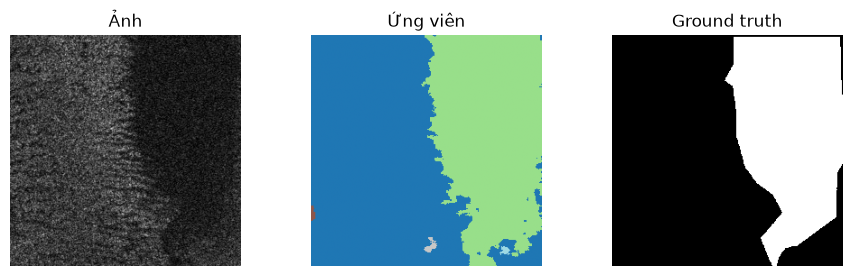

In [2]:
from sar_oil.pipeline import candidates
selected=load('selected.json')
a,g=read_pair(next(r for r in records('validation') if not r['empty']))
f,l=candidates(a,selected['config']); X,ids=core.features(f,l); R,_=reference.features(f,l)
print('Sai số đặc trưng:',np.max(np.abs(X-R)) if X.size else 0)
table([dict(region=i,**dict(zip(core.FEATURES,x))) for i,x in zip(ids,X)][:15],['region']+core.FEATURES)
fig,axes=plt.subplots(1,3,figsize=(11,3))
for j,(ax,img,title) in enumerate(zip(axes,[a,l,g],['Ảnh','Ứng viên','Ground truth'])): ax.imshow(img,cmap='tab20' if j==1 else 'gray',vmin=0,vmax=max(1,l.max()) if j==1 else 1); ax.set_title(title); ax.axis('off')
plt.show()

In [3]:
rows=load('validation.json')
best_by_group=[next(r for r in rows if r['group']==group) for group in ('shape','intensity','all')]
table([dict(group=r['group'],kind=r['kind'],morphology=str(r['config']['morphology']),**r['metrics']) for r in best_by_group],['group','kind','morphology','precision','recall','f1'])

group,kind,morphology,precision,recall,f1
shape,cart,"{'operation': 'close', 'min_area': 64}",0.333701,0.331022,0.332356
intensity,svm,"{'operation': 'none', 'min_area': 64}",0.314107,0.365693,0.337943
all,svm,"{'operation': 'none', 'min_area': 64}",0.314454,0.370803,0.340312
